# pandas: первый взгляд на данные

ФПМИ.Будущее · ИИ · Прекурс · Занятие 3

pandas — это таблица с названиями столбцов поверх NumPy. Всё, что мы делали с массивами — маски, поэлементные операции, `mean` и `sum`, — работает и здесь.

Настоящие данные приходят файлом: текст, даты, пустые ячейки, ошибки ввода. Прежде чем что-то предсказывать, таблицу нужно открыть, понять и почистить. Сегодня сделаем это на одном датасете — заказах интернет-магазина за полгода.

Главная привычка: сначала посмотреть на таблицу глазами, потом считать. Файлы `orders.csv` и `products.csv` лежат в папке `data/` рядом с ноутбуком.

## 1. Открываем файл: `read_csv`, `head`, `shape`

`pd.read_csv` читает CSV в **DataFrame** — таблицу с названиями столбцов. Первое, что делают с любой таблицей, — смотрят на неё: `head()` показывает первые пять строк.

In [2]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)

orders = pd.read_csv("data/orders.csv")
orders.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data/orders.csv'

In [ ]:
print("Форма таблицы:", orders.shape)
print("Столбцы:", list(orders.columns))

Строка — объект (один заказ), столбец — признак. Слева серым — **индекс**, номер строки. Уже в первых строках видны `NaN` — пустые ячейки, к ним вернёмся.

`tail()` показывает последние строки, `sample(5)` — пять случайных.

## 2. Описание таблицы: `info` и `describe`

`info()` показывает тип каждого столбца и сколько в нём **непустых** значений.

In [ ]:
orders.info()

`int64` и `float64` — числа, `object` — чаще всего текст. Строк 2500, но в `delivery_days` непустых 2408, а в `rating` — только 1486. Остальное — пропуски.

`describe()` считает статистики по всем числовым столбцам сразу: `count` — сколько непустых, `mean` и `std` — среднее и разброс, дальше минимум, квартили, медиана (`50%`) и максимум.

In [ ]:
orders.describe().round(1)

Две странности: у `price` максимум в сотни раз больше 75-го процентиля, а у `delivery_days` минимум отрицательный. Это выбросы, разберём их в разделе 9.

Для текстовых столбцов есть свой `describe`: сколько уникальных значений и какое самое частое.

In [ ]:
orders.describe(include="object")

## 3. Столбцы и новый признак

Один столбец берём по имени: `orders["price"]`. С ним работают как с массивом NumPy: `mean`, `median`, сравнения. Внутри действительно массив NumPy — его показывает `.values`.

In [ ]:
price = orders["price"]

print("Среднее:", price.mean())
print("Медиана:", price.median())
print("Внутри — массив NumPy:", price.values[:5])

In [ ]:
# Несколько столбцов — список названий.
orders[["city", "price", "quantity"]].head()

Операции над столбцами — поэлементные, без циклов, как в NumPy. Так появляются новые признаки: сумма заказа — это цена, умноженная на количество.

In [ ]:
orders["amount"] = orders["price"] * orders["quantity"]

orders[["price", "quantity", "amount"]].head()

## 4. Булева маска: фильтр без цикла

Сравнение столбца со значением выполняется для каждой строки и создаёт столбец из `True` и `False`. Маска в квадратных скобках оставляет только строки с `True`.

In [ ]:
mask = orders["city"] == "Казань"

print("Маска:", mask.values[:5])
print("Заказов из Казани:", mask.sum())
print("Доля заказов из Казани:", mask.mean().round(3))

In [ ]:
kazan = orders[mask]

print("Форма:", kazan.shape)
kazan.head()

In [ ]:
print("Средний чек в Казани:", kazan["amount"].mean().round(2))
print("То же самое через .loc[строки, столбец]:", orders.loc[mask, "amount"].mean().round(2))

Несколько условий: `&` — «и», `|` — «или», `~` — «не». Каждое условие берётся в скобки, иначе Python попытается сначала применить `&` к строке и столбцу и упадёт с ошибкой.

In [ ]:
kazan_card = orders[(orders["city"] == "Казань") & (orders["payment"] == "карта")]
two_capitals = orders[orders["city"].isin(["Москва", "Санкт-Петербург"])]

print("Казань и оплата картой:", kazan_card.shape)
print("Москва или Петербург:", two_capitals.shape)

### Мини-задача 1. Фильтр по двум условиям

Выберите из `orders` заказы из Санкт-Петербурга, доставленные за 3 дня или быстрее.

In [ ]:
# spb_fast = ...

In [ ]:
assert (spb_fast["city"] == "Санкт-Петербург").all()
assert (spb_fast["delivery_days"] <= 3).all()

print("Мини-задача 1: тесты пройдены")

<details>
<summary>Показать решение</summary>

```python
spb_fast = orders[(orders["city"] == "Санкт-Петербург") & (orders["delivery_days"] <= 3)]
```

</details>

## 5. Пропуски

Пустая ячейка в pandas — `NaN`. Пропуски есть почти в любых реальных данных: кто-то не поставил оценку, заказ ещё не доставлен, датчик не сработал.

`isna()` превращает таблицу в `True` и `False`. Как и в NumPy, `sum()` маски — количество, `mean()` — доля.

In [ ]:
print("Пропусков в каждом столбце:")
print(orders.isna().sum())

In [ ]:
print("Доля пропусков:")
print(orders.isna().mean().round(3))

Оценку ставят не все — 41% пропусков. 4% заказов ещё в пути — у них нет `delivery_days`.

Что с пропусками делать:

- ничего: `mean()`, `sum()` и `describe()` сами пропускают `NaN`;
- удалить строки — `dropna`; дёшево, но теряем данные;
- заполнить — `fillna`: медианой, нулём, отдельной меткой.

Сам факт пропуска — тоже признак: «не поставил оценку» — это информация.

In [ ]:
print("Средняя оценка, NaN пропускаются:", orders["rating"].mean().round(3))
print("Строк после dropna по доставке:", orders.dropna(subset=["delivery_days"]).shape[0])

In [ ]:
orders["rating_filled"] = orders["rating"].fillna(orders["rating"].median())
orders["rating_missing"] = orders["rating"].isna().astype(int)

orders[["rating", "rating_filled", "rating_missing"]].head(8)

### Мини-задача 2. Доля пропусков

Найдите долю пропусков в столбце `delivery_days`.

Ожидаемый ответ: число от `0` до `1`, около `0.037`.

Заполните ячейку и запустите проверку. `np.isclose` сравнивает числа с учётом небольших погрешностей.

In [ ]:
# delivery_missing_share = ...

In [ ]:
assert np.isclose(delivery_missing_share, 0.0368, atol=1e-4)

print("Мини-задача 2: тесты пройдены")

<details>
<summary>Показать решение</summary>

```python
delivery_missing_share = orders["delivery_days"].isna().mean()
```

</details>

## 6. Числовые и категориальные признаки

Модель работает только с числами. Числовые столбцы — цена, количество, дни доставки — можно складывать и усреднять. Категориальные — город, способ оплаты — это набор ярлыков, «средний город» не существует.

Для категориального столбца главный инструмент — `value_counts()`.

In [ ]:
print(orders.dtypes)

In [ ]:
print(orders["city"].value_counts())

In [ ]:
# normalize=True — доли вместо количества.
print(orders["payment"].value_counts(normalize=True).round(2))

Не всё, что выглядит числом, — число. `product_id` — ярлык товара, среднее по нему в `describe()` бессмысленно. `returned` — это «да» или «нет», а не количество.

Чтобы отдать категорию модели, её кодируют числами. Самый простой способ — **one-hot**: одна категория превращается в несколько столбцов из `0` и `1`.

In [ ]:
pd.get_dummies(orders["payment"], dtype=int).head()

## 7. `groupby`: считаем по группам

Вопрос «средний чек по городам» — это три шага: разбить строки по значению `city`, в каждой группе взять `amount`, посчитать среднее.

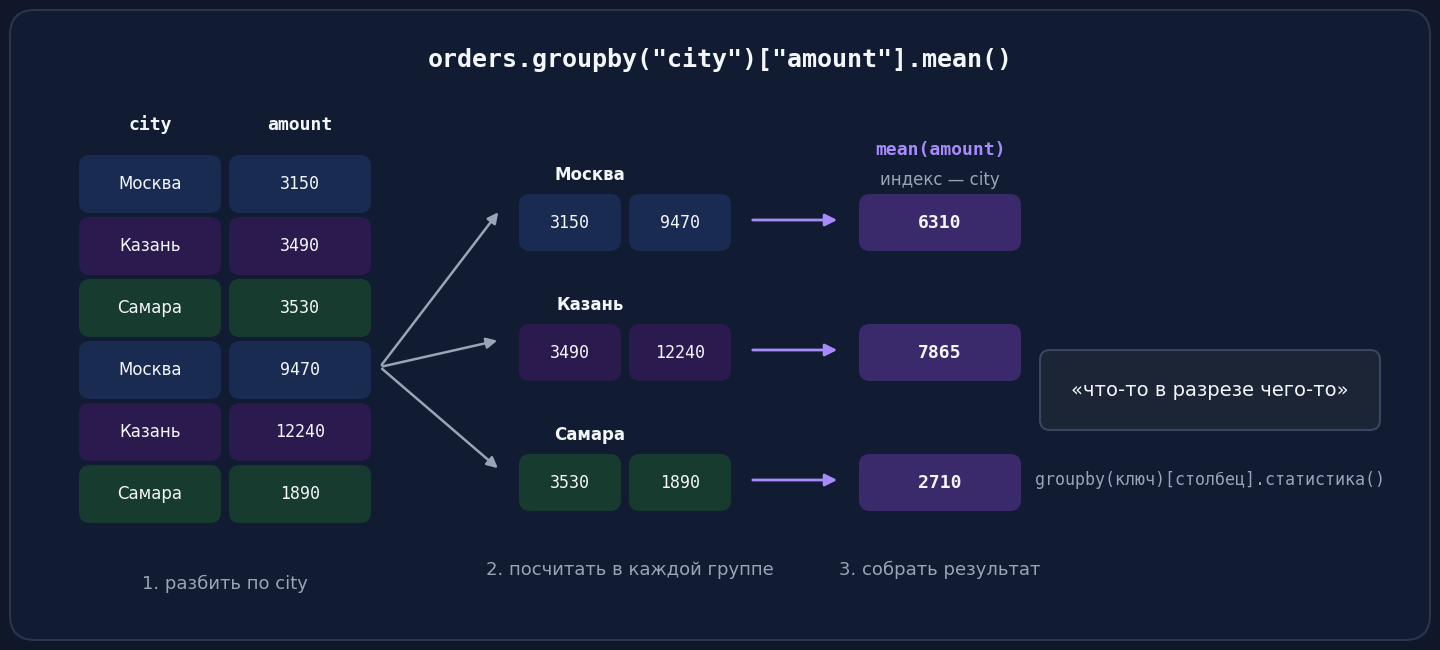

In [ ]:
mean_by_city = orders.groupby("city")["amount"].mean().round(0)
print(mean_by_city)

Екатеринбург вдвое дороже Москвы, Казань — в полтора раза. Подозрительно. `agg` со списком считает несколько статистик сразу.

In [ ]:
orders.groupby("city")["amount"].agg(["mean", "median", "count"]).round(0)

Медианы у всех городов почти одинаковые, а средние разъехались. Так выглядят выбросы: несколько огромных чисел тянут среднее вверх, на медиану они не влияют.

`groupby` отвечает на любой вопрос вида «что-то в разрезе чего-то».

In [ ]:
print("Доля возвратов по способу оплаты:")
print(orders.groupby("payment")["returned"].mean().round(3))
print()
print("Средняя доставка по городам, дней:")
print(orders.groupby("city")["delivery_days"].mean().sort_values().round(1))

### Мини-задача 3. Среднее по группам

Найдите среднюю оценку `rating` для каждого способа оплаты.

Ожидаемый ответ: три числа, по одному на каждый способ оплаты, с названиями способов в индексе.

Заполните ячейку и запустите проверку. `np.allclose` сравнивает числовые массивы с учётом погрешностей.

In [ ]:
# rating_by_payment = ...

In [ ]:
assert rating_by_payment.shape == (3,)
assert np.isclose(rating_by_payment["наличные"], 3.853, atol=1e-3)
assert rating_by_payment.idxmax() == "карта"

print("Мини-задача 3: тесты пройдены")

<details>
<summary>Показать решение</summary>

```python
rating_by_payment = orders.groupby("payment")["rating"].mean()
```

</details>

## 8. `merge`: приклеиваем вторую таблицу

Категория товара лежит не в заказах, а в справочнике `products.csv`. Общий столбец — `product_id`. `merge` соединяет таблицы по нему: к каждому заказу подставляется строка нужного товара.

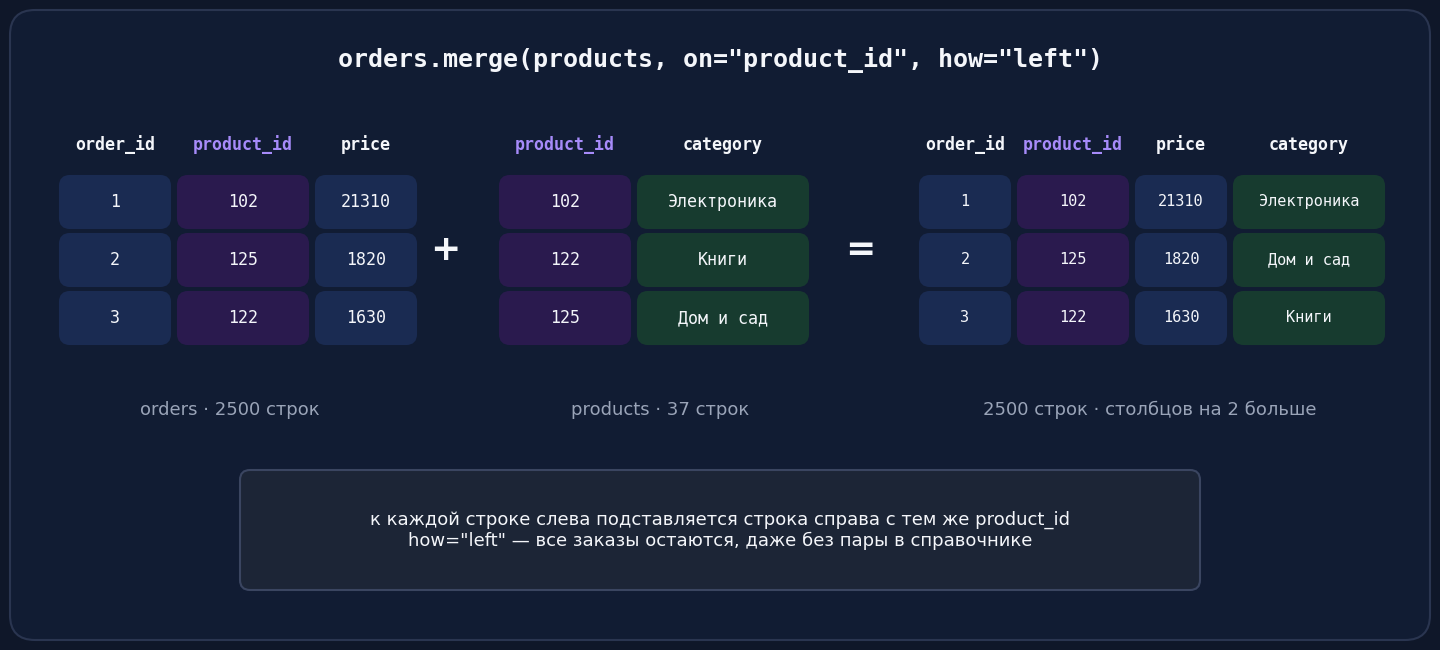

In [ ]:
products = pd.read_csv("data/products.csv")

print("Форма справочника:", products.shape)
products.head()

In [ ]:
# how="left": сохраняем все заказы, даже если товар в справочнике не нашёлся.
df = orders.merge(products, on="product_id", how="left")

print("Было:", orders.shape)
print("Стало:", df.shape)
df[["order_id", "product_id", "name", "category", "amount"]].head()

Строк столько же, столбцов на два больше. Проверять форму после `merge` — обязательная привычка: если строк стало больше, ключ в справочнике не уникален и таблица «размножилась».

In [ ]:
print("Выручка по категориям:")
print(df.groupby("category")["amount"].sum().sort_values(ascending=False))
print()
print("Доля возвратов по категориям:")
print(df.groupby("category")["returned"].mean().sort_values(ascending=False).round(3))

> Одежду возвращают в пять-шесть раз чаще, чем книги. Это первый настоящий факт о данных — и первый сигнал для будущей модели.

## 9. Выбросы: `describe` и гистограмма

Выброс — значение, которое сильно отличается от остальных. Иногда это ошибка ввода, иногда редкое настоящее событие. В обоих случаях его надо заметить: выбросы ломают среднее и мешают модели.

Два инструмента: `describe()` — сравниваем `max` с `75%` — и гистограмма.

In [ ]:
print(orders["price"].describe().round(0))

In [ ]:
import matplotlib.pyplot as plt

plt.style.use("dark_background")
plt.figure(figsize=(8, 4.5))
plt.hist(orders["price"], bins=50)
plt.xlabel("Цена, руб.")
plt.ylabel("Число заказов")
plt.title("Все цены")
plt.tight_layout()
plt.show()

Один столбик у нуля и пустота до полутора миллионов: все обычные цены сжались в первый столбец. Посмотрим, кто это.

In [ ]:
orders.sort_values("price", ascending=False).head(4)

Клавиатура за полтора миллиона — лишние нули при вводе. Уберём всё дороже 500 000 и посмотрим на гистограмму снова.

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.hist(orders.loc[orders["price"] < 500_000, "price"], bins=50)
plt.xlabel("Цена, руб.")
plt.ylabel("Число заказов")
plt.title("Цены без трёх выбросов")
plt.tight_layout()
plt.show()

Теперь видно распределение: большинство товаров дешевле 10 000, длинный хвост дорогих. Такой «хвост вправо» обычен для цен и зарплат.

Теперь `delivery_days`: отрицательные значения и очень большие.

In [ ]:
print("Отрицательная доставка:")
print(orders.loc[orders["delivery_days"] < 0, ["order_id", "city", "delivery_days"]])
print()
print("Доставка дольше 30 дней:")
print(orders.loc[orders["delivery_days"] > 30, ["order_id", "city", "delivery_days"]])

Отрицательная доставка — ошибка, превращаем в пропуск. 45–120 дней — скорее всего потерянные посылки: редкие, но настоящие случаи, оставляем.

`.copy()` нужен, чтобы pandas не предупреждал, что мы меняем «кусок» другой таблицы.

In [ ]:
clean = orders[orders["price"] < 500_000].copy()
clean.loc[clean["delivery_days"] < 0, "delivery_days"] = np.nan

print("Строк осталось:", clean.shape[0])
print()
print("Средний чек по городам без выбросов:")
print(clean.groupby("city")["amount"].mean().round(0))

> Казань: было 14 935, стало 8 594. Три строки из 2500 меняли всю картину — поэтому в незнакомую таблицу сначала смотрят и только потом считают.

## 10. Задача C1

Напишите функцию `mean_check(orders, city)`. На вход поступает таблица заказов и название города. Верните средний чек заказов из этого города — чек заказа это `price × quantity`, — округлённый до двух знаков.

Считайте по исходной таблице `orders.csv`, ничего не удаляя. Сначала напишите функцию, затем запустите ячейку с тестами.

In [ ]:
raw = pd.read_csv("data/orders.csv")

def mean_check(orders, city):
    # Напишите решение здесь.
    pass

In [ ]:
assert np.isclose(mean_check(raw, "Москва"), 9485.24)
assert np.isclose(mean_check(raw, "Самара"), 7827.78)
assert np.isclose(mean_check(raw, "Казань"), 14934.94)

print("Тесты пройдены")

<details>
<summary>Показать решение</summary>

```python
def mean_check(orders, city):
    amount = orders["price"] * orders["quantity"]
    return round(amount[orders["city"] == city].mean(), 2)
```

</details>

## Главное после урока

```python
orders = pd.read_csv("data/orders.csv")
orders.head(); orders.info(); orders.describe()

orders["amount"] = orders["price"] * orders["quantity"]
orders[(orders["city"] == "Казань") & (orders["payment"] == "карта")]
orders.loc[mask, "amount"].mean()

orders.isna().mean()
orders["rating"].fillna(orders["rating"].median())

orders["city"].value_counts()
orders.groupby("city")["amount"].agg(["mean", "median", "count"])
orders.merge(products, on="product_id", how="left")
```